# Problem 1

We saw a simple CNN notebook (1_pytorch_basic_cnn_digits.ipynb) where 
digits from Sklearn were used and a classification model was created. You will expand 
on that work and instead of sklearn dataset, use the MNIST dataset from torchvision 
where images are of size 28 x 28. Build model with torchvision Dataset. Next draw a few 
numbers in your own handwriting and see if the model can detect it, just inference. Do 
not over do this.

In [1]:
# 1. Setup and imports
import random
import numpy as np
import matplotlib.pyplot as plt

import torchvision
import torchvision.transforms.v2 as T

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Random processes are used when splitting and shuffling data and when
# initializing model weights. A fixed seed makes results more repeatable.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
from torch.utils.data import random_split

# Apple Silicon use MPS; laptops with NVIDIA GPUs can use CUDA.
# This tiny dataset also trains quickly on a CPU. So dont worry
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")

PyTorch version: 2.14.0+rocm7.14
Using device: cuda


Training images shape: torch.Size([1, 28, 28])
Testing images shape: torch.Size([1, 28, 28])
Number of training images: 60000
Number of testing images: 10000
(training) Class Names  ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Minimum pixel value: 0.0
Maximum pixel value: 1.0


/home/zoe/Github/deep_learning_course/.venv-1/lib/python3.12/site-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


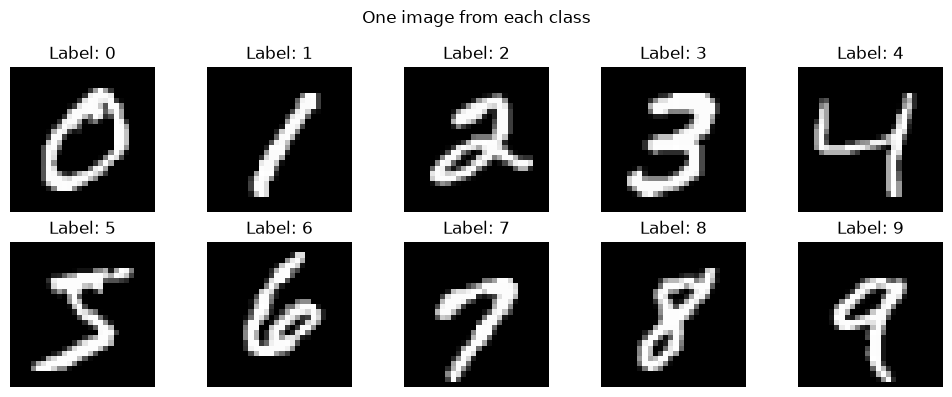

In [2]:
# 2. Load and explore the images

toTensor = T.ToTensor()
train_data = torchvision.datasets.MNIST(
    root="datasets", train=True, download=True, transform=toTensor)
test_data = torchvision.datasets.MNIST(
    root="datasets", train=False, download=True, transform=toTensor)

print(f"Training images shape: {train_data[0][0].shape}")
print(f"Testing images shape: {test_data[0][0].shape}")
print(f"Number of training images: {len(train_data)}")
print(f"Number of testing images: {len(test_data)}")


class_names = train_data.classes
print("(training) Class Names ", class_names)


print(f"Minimum pixel value: {train_data[0][0].min()}")
print(f"Maximum pixel value: {train_data[0][0].max()}")

images = train_data.data.numpy()
labels = train_data.targets.numpy()

# Display one example from each class.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    example_index = np.where(labels == digit)[0][0]
    ax.imshow(images[example_index], cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")
plt.suptitle("One image from each class")
plt.tight_layout()
plt.show()

## 3. Create training, validation, and test datasets

Note, I am using 10% for testing and 10% for validation. The test set is 20% of the full amount, so I am spliting it in 2. The training data is being left as is at 80%. 

This dataset comes prenormalized (values between 0 and 1) and the dataloader below outputs labels as type `torch.int64`, so no further preprocessing is necessary.

In [3]:
validating_data, testing_data = random_split(
    test_data,
    [5000, 5000]
)

## 4. Put the data into DataLoaders

We will use  `TensorDataset` that pairs every image with its label. And also `DataLoader` which serves small batches to the model. Training data is shuffled each epoch so the model does not learn from a fixed ordering. Validation and test data do not need shuffling.

`train_generator` creates a random-number generator with a fixed starting point. in our case it controls how the DataLoader shuffles the training images


In [4]:
BATCH_SIZE = 64

train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator = train_generator
)

test_loader = DataLoader(
    testing_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    validating_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)


batch_images, batch_labels = next(iter(train_loader))
print(f"Image batch shape: {batch_images.shape}")
print(f"Label batch shape: {batch_labels.shape}")

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


## 5. Define a vanilla CNN

The network has two conceptual parts:

- **Feature extractor:** convolution layers slide small filters across the image. ReLU adds non-linearity, and max pooling reduces width and height.
- **Classifier:** the feature maps are flattened into a vector and passed to a linear layer that produces 10 class scores, called **logits**.

Shape changes: `(1, 28, 28) → (8, 28, 28) → (8, 14, 14) → (16, 14, 14) → (16, 7, 7) → 64 → 10`.

In [5]:
class BasicCNN(nn.Module):
    """A small CNN for 8 x 8, one-channel images."""

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Padding=1 keeps height and width at 8 x 8.
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1),
            nn.ReLU(),
            # Pooling changes 8 x 8 into 4 x 4.
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            # Pooling changes 4 x 4 into 2 x 2.
            nn.MaxPool2d(kernel_size=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),                    # 16 feature maps x 2 x 2 = 64 values
            nn.Linear(16 * 2 * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 10),              # One score for each digit
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = BasicCNN().to(device)
print(model)

# Confirm that a batch produces one row of 10 scores per image.
with torch.no_grad():
    example_output = model(batch_images.to(device))
print(f"Model output shape: {example_output.shape}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

BasicCNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=10, bias=True)
  )
)


MIOpen(HIP): Warning [OpenRuntimeLibraryForDevice] CK grouped conv library not found for device gfx1030: libMIOpenCKGroupedConv_gfx1030.so: cannot open shared object file: No such file or directory


RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x784 and 64x32)

## 6. Loss, optimizer, and evaluation function

`CrossEntropyLoss` compares the 10 raw class scores with the correct class. It already performs the softmax-related mathematics internally, so we **do not add a softmax layer** to the model.

The Adam optimizer updates weights to reduce loss. During evaluation, `model.eval()` turns off training-only behavior, and `torch.no_grad()` avoids storing gradients, saving memory.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)

def evaluate(model, data_loader, criterion, device):
    """Return average loss and accuracy without changing model weights."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = model(inputs)
            loss = criterion(logits, targets)
            predictions = logits.argmax(dim=1)

            # Multiply by batch size because loss is an average for this batch.
            total_loss += loss.item() * inputs.size(0)
            total_correct += (predictions == targets).sum().item()
            total_examples += inputs.size(0)

    return total_loss / total_examples, total_correct / total_examples

## 7. Train the model

For each batch, training follows five steps: 
            clear old gradients, 
            make predictions, 
            calculate loss, 
            calculate gradients with backpropagation, 
            and update the weights. 

One complete pass through the training set is an **epoch**.

Logits are the raw scores the model produces for each possible class.
Logits are not probabilities: they can be negative and don’t need to sum to 1.

 Digit:  0    1     2    3    4    5    6    7    8    9
 Logits:
        [0.2, -1.0, 0.5, 3.1, 0.0, 0.8, -0.4, 1.2, 0.3, 0.1]

The highest score is 3.1 at index 3, so the predicted digit is 3.

During training, pass these raw scores directly to CrossEntropyLoss, PyTorch’s nn.CrossEntropyLoss already includes the probability-conversion calculation, so you give it the raw logits.

Conceptually, it does two things:
1. Converts logits into probabilities using softmax.
2. Calculates the loss from the probability assigned to the correct class

If you apply softmax first, CrossEntropyLoss treats those probabilities as raw scores and normalizes them again, changing the intended calculation.

In [ ]:
EPOCHS = 30
history = {
    "train_loss": [], "train_accuracy": [],
    "val_loss": [], "val_accuracy": [],
}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_examples = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()          # 1. Clear gradients from the previous batch.
        logits = model(inputs)         # 2. Forward pass: compute class scores.
        loss = criterion(logits, targets)  # 3. Measure prediction error.
        loss.backward()                # 4. Backward pass: compute gradients.
        optimizer.step()               # 5. Update the model's weights.

        predictions = logits.argmax(dim=1)
        running_loss += loss.item() * inputs.size(0)
        running_correct += (predictions == targets).sum().item()
        running_examples += inputs.size(0)

    train_loss = running_loss / running_examples
    train_accuracy = running_correct / running_examples
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.3f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.3f}"
    )

Epoch 01/30 | train loss 2.2845, accuracy 0.111 | val loss 2.2262, accuracy 0.248
Epoch 02/30 | train loss 2.0541, accuracy 0.430 | val loss 1.7402, accuracy 0.581
Epoch 03/30 | train loss 1.3566, accuracy 0.648 | val loss 1.0158, accuracy 0.722
Epoch 04/30 | train loss 0.7908, accuracy 0.776 | val loss 0.7208, accuracy 0.785
Epoch 05/30 | train loss 0.5216, accuracy 0.850 | val loss 0.5334, accuracy 0.848
Epoch 06/30 | train loss 0.4140, accuracy 0.861 | val loss 0.4313, accuracy 0.874
Epoch 07/30 | train loss 0.3348, accuracy 0.898 | val loss 0.3274, accuracy 0.885
Epoch 08/30 | train loss 0.2696, accuracy 0.919 | val loss 0.2863, accuracy 0.900
Epoch 09/30 | train loss 0.2326, accuracy 0.924 | val loss 0.2494, accuracy 0.926
Epoch 10/30 | train loss 0.2060, accuracy 0.939 | val loss 0.2239, accuracy 0.933
Epoch 11/30 | train loss 0.1782, accuracy 0.943 | val loss 0.2111, accuracy 0.933
Epoch 12/30 | train loss 0.1656, accuracy 0.947 | val loss 0.2199, accuracy 0.922
Epoch 13/30 | tr

## 8. Plot the learning curves

Loss measures error (lower is better), while accuracy is the fraction predicted correctly (higher is better). If training keeps improving while validation gets worse, the model may be overfitting.

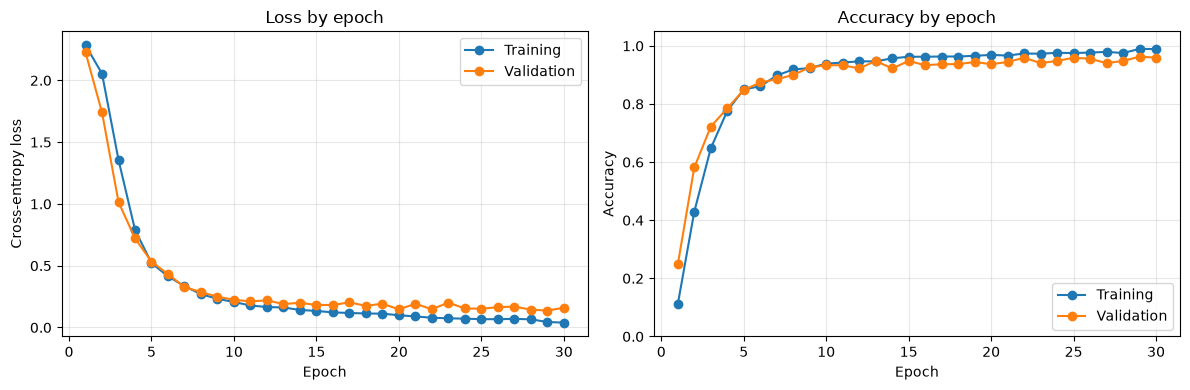

In [ ]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Final evaluation on the untouched test set

We use the test set only after training is finished. Besides overall loss and accuracy, the classification report shows precision, recall, and F1-score for every digit. The confusion matrix shows which digits are confused with one another.

Test loss:     0.1044
Test accuracy: 97.04%
Accuracy check with scikit-learn: 97.04%

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        27
           1       1.00      0.79      0.88        28
           2       0.96      1.00      0.98        26
           3       0.97      1.00      0.98        28
           4       1.00      1.00      1.00        27
           5       1.00      1.00      1.00        27
           6       1.00      0.96      0.98        27
           7       1.00      1.00      1.00        27
           8       0.81      0.96      0.88        26
           9       1.00      1.00      1.00        27

    accuracy                           0.97       270
   macro avg       0.97      0.97      0.97       270
weighted avg       0.97      0.97      0.97       270



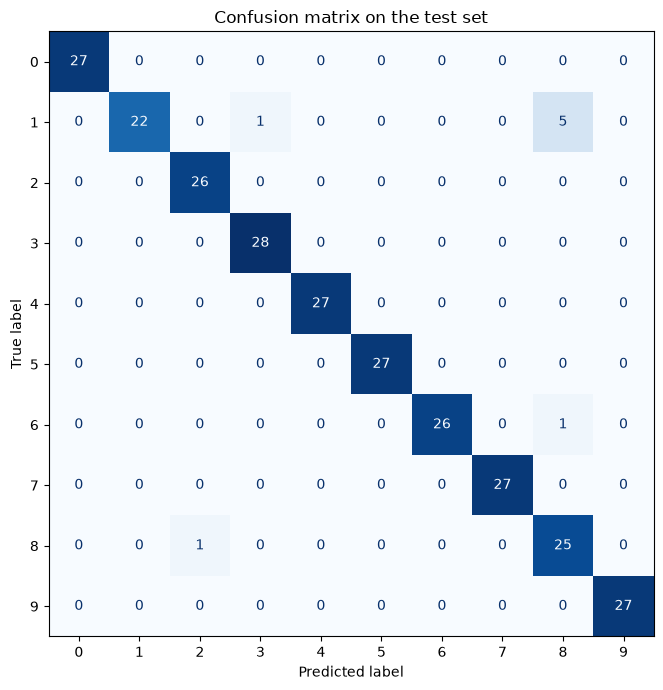

In [ ]:
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

# Collect every test prediction on the CPU for scikit-learn metrics.
model.eval()
all_predictions = []
all_targets = []
with torch.no_grad():
    for inputs, targets in test_loader:
        logits = model(inputs.to(device))
        predictions = logits.argmax(dim=1).cpu()
        all_predictions.extend(predictions.numpy())
        all_targets.extend(targets.numpy())

print(f"Accuracy check with scikit-learn: {accuracy_score(all_targets, all_predictions):.2%}")
print("\nClassification report:")
print(classification_report(all_targets, all_predictions, target_names=[str(x) for x in class_names]))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    all_targets, all_predictions, display_labels=class_names, cmap="Blues", ax=ax, colorbar=False
)
ax.set_title("Confusion matrix on the test set")
plt.tight_layout()
plt.show()

### How to read the metrics

- **Accuracy:** proportion of all predictions that were correct.
- **Precision for a digit:** when the model predicts this digit, how often is it correct?
- **Recall for a digit:** of all real examples of this digit, how many did the model find?
- **F1-score:** a combined measure of precision and recall.
- **Support:** number of test examples belonging to that digit.
- **Confusion matrix:** correct predictions are on the main diagonal; off-diagonal cells are mistakes.

## 10. Look at individual predictions

A metric summarizes performance, but seeing individual examples makes the result more concrete. Green titles are correct predictions and red titles are mistakes.

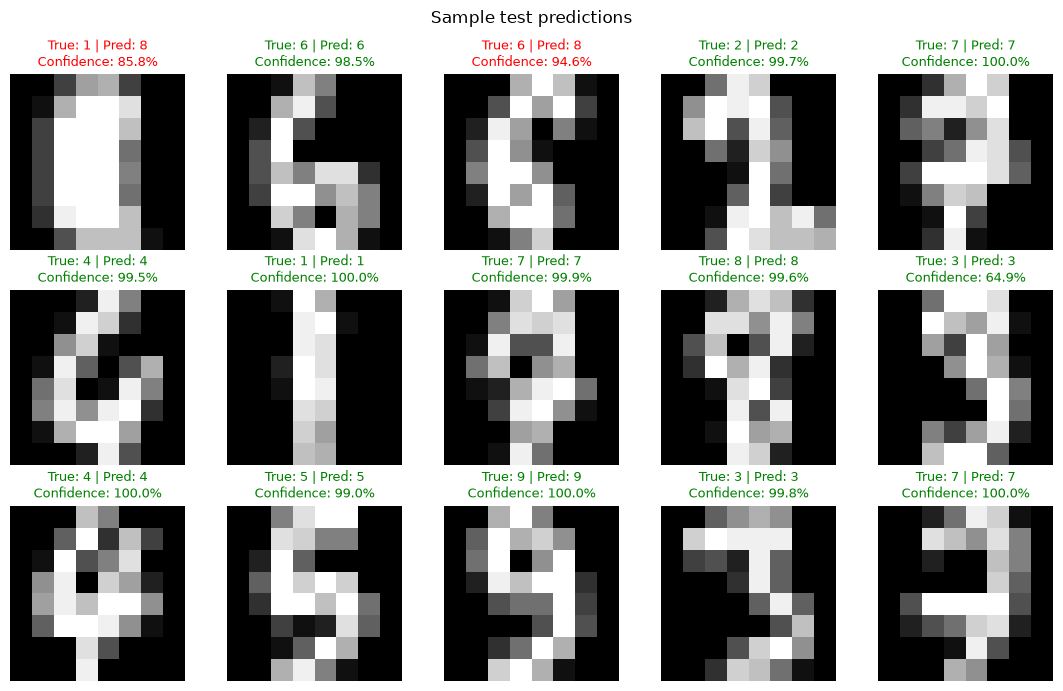

In [ ]:
# Use a fixed random generator so the displayed sample is repeatable.
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_test_t), size=15, replace=False)

model.eval()
with torch.no_grad():
    sample_logits = model(X_test_t[sample_indices].to(device))
    sample_probabilities = torch.softmax(sample_logits, dim=1).cpu()
    sample_predictions = sample_probabilities.argmax(dim=1)

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, index, prediction, probabilities in zip(
    axes.flat, sample_indices, sample_predictions, sample_probabilities
):
    actual = int(y_test_t[index])
    predicted = int(prediction)
    confidence = float(probabilities[predicted])
    color = "green" if predicted == actual else "red"

    ax.imshow(X_test_t[index, 0], cmap="gray")
    ax.set_title(
        f"True: {actual} | Pred: {predicted}\nConfidence: {confidence:.1%}",
        color=color, fontsize=9
    )
    ax.axis("off")

plt.suptitle("Sample test predictions")
plt.tight_layout()
plt.show()

## 11. Save and reload the trained model (optional)

Saving a `state_dict` stores the learned weights. To use them later, create the same architecture and load the weights into it.

In [ ]:
MODEL_PATH = "basic_cnn_digits.pth"
torch.save(model.state_dict(), MODEL_PATH)
print(f"Saved weights to {MODEL_PATH}")

# Example reload:
reloaded_model = BasicCNN().to(device)
reloaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
reloaded_model.eval()
reloaded_loss, reloaded_accuracy = evaluate(reloaded_model, test_loader, criterion, device)
print(f"Reloaded model test accuracy: {reloaded_accuracy:.2%}")

Saved weights to basic_cnn_digits.pth
Reloaded model test accuracy: 97.04%


## Summary

Through this example we have used a CNN and seen a full image-classification workflow: data loading, splitting, preprocessing, batching, CNN construction, training, validation, final testing, metrics, visualization, and saving weights. 

# Problem 2

*As part of the 2_pytorch_CNN_Classify_flowers.ipynb we saw the model 
was trained to a 75% accuracy. Change the hyper parameters – add new layers, change 
activation functions, experiment with different kernel sizes, experiment pooling layers 
types and see if you can increase the accuracy of the model. You should add 2 more 
convolutional layers (blocks) and make the network even deeper, also add one additional 
linear layer with RELU activation. Document your experiments in detail, don’t overdo 
this and ensure to not overfit. Do not worry about doing any Data augmentation 
techniques at this point.*


We will train a small convolutional neural network **from scratch** on real color photographs. No pretrained weights are used, that will be discussed next week in the class. 

We will download images, inspect labels, create separate training/validation/test sets, resize images, build a classification CNN, train it, and evaluate predictions. Unlike the previous 8×8 digits example, these images have three color channels and varied backgrounds, so the task is harder.

The first run needs internet access and disk space for the downloaded images. Or you can download ahead of time.

Downloads are reused on subsequent runs. Training time depends on your computer; a GPU will help. 

The default is 15 epochs and 64×64 images to keep this manageable.  

We will do 50 epochs and also make a point around why its important to keep an eye on the Validataion and Test loss.

## 1. Install packages and import tools

If the imports fail, uncomment the installation line, run it once, then restart the kernel. TensorFlow is not required, even for the Flower Photos dataset.

In [1]:
# %pip install torch torchvision scikit-learn matplotlib pillow

from pathlib import Path
import copy
import json
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay,
)

# Seeds make the split and initial weights repeatable, but do not guarantee
# identical floating-point results across all devices or PyTorch versions.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)  # Avoid excessive CPU thread overhead on this small model.
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 0.001
DATA_DIR = Path('../data')
DATA_DIR.mkdir(exist_ok=True)
print('PyTorch:', torch.__version__, '| Device:', device)

PyTorch: 2.14.0+rocm7.14 | Device: cuda


## 2. Download Flower Photos and read the labels

The [Flower Photos dataset](https://www.tensorflow.org/tutorials/images/classification) has 3,670 photographs in five folders: daisy, dandelion, roses, sunflowers, and tulips. The archive is approximately 220 MB. 

`ImageFolder` daisy, roses etc -assigns labels from alphabetically sorted folder names. We read that mapping instead of guessing the numbers. This dataset has no official test split, so we will make a reproducible stratified 70%/15%/15% split.

In [2]:
flower_root = DATA_DIR / 'flower_photos'
if not flower_root.exists():
    download_and_extract_archive(
        'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
        download_root=str(DATA_DIR),
    )
catalog = datasets.ImageFolder(flower_root)
class_names = catalog.classes
# Each record is (path_to_image, integer_class_label).
records = [(Path(path), label) for path, label in catalog.samples]
labels = [label for _, label in records]
train_records, remaining = train_test_split(
    records, test_size=0.30, random_state=SEED, stratify=labels)
val_records, test_records = train_test_split(
    remaining, test_size=0.50, random_state=SEED,
    stratify=[label for _, label in remaining])
print('Folder-to-label mapping:', catalog.class_to_idx)

100%|██████████| 229M/229M [00:23<00:00, 9.63MB/s] 


Folder-to-label mapping: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


## 3. Check the split and look at real images

Training images teach the weights. Validation images select the best epoch. Test images are reserved for final evaluation, after those decisions. Never adjust settings based on test results; use validation results for experiments.

Train: 2569 images | {'daisy': 443, 'dandelion': 629, 'roses': 449, 'sunflowers': 489, 'tulips': 559}
Validation: 550 images | {'daisy': 95, 'dandelion': 134, 'roses': 96, 'sunflowers': 105, 'tulips': 120}
Test: 551 images | {'daisy': 95, 'dandelion': 135, 'roses': 96, 'sunflowers': 105, 'tulips': 120}


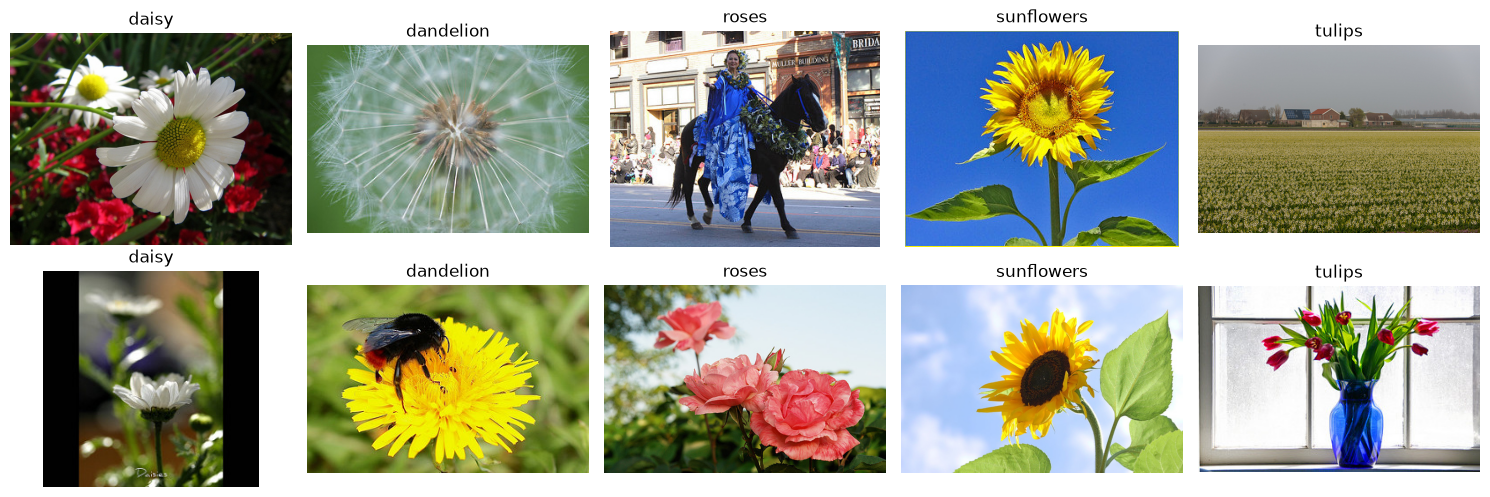

In [3]:
# A path must appear in only one split: this checks for accidental overlap.
train_paths = {path for path, _ in train_records}
val_paths = {path for path, _ in val_records}
test_paths = {path for path, _ in test_records}
assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)
for name, records in [('Train', train_records), ('Validation', val_records), ('Test', test_records)]:
    counts = np.bincount([label for _, label in records], minlength=len(class_names))
    print(f'{name}: {len(records)} images | {dict(zip(class_names, counts.tolist()))}')

# Show two training examples per class, before resizing.
fig, axes = plt.subplots(2, len(class_names), figsize=(3 * len(class_names), 5), squeeze=False)
for label, name in enumerate(class_names):
    examples = [path for path, target in train_records if target == label][:2]
    for row, path in enumerate(examples):
        with Image.open(path) as picture:
            axes[row, label].imshow(picture.convert('RGB'))
        axes[row, label].set_title(name)
        axes[row, label].axis('off')
plt.tight_layout()
plt.show()

## 4. Convert images into tensors and batches

Photos vary in size. We resize each one to 64×64 pixels (this simple resize can distort aspect ratios). `ToTensor` changes pixels from integers in 0–255 to floats in 0–1 and rearranges the dimensions to **channels, height, width**. RGB means three channels: red, green, blue.

A small custom `Dataset` loads one image when requested instead of keeping every full-resolution image in memory. `DataLoader` collects these images into batches. Only training batches are shuffled. This baseline uses the same deterministic preprocessing for all splits; augmentation can be a later experiment.

In [4]:
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

class PhotoDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path, label = self.records[index]
        with Image.open(path) as picture:
            # Convert even grayscale/RGBA files to three-channel RGB.
            image = self.transform(picture.convert('RGB'))
        return image, label

train_dataset = PhotoDataset(train_records, image_transform)
val_dataset = PhotoDataset(val_records, image_transform)
test_dataset = PhotoDataset(test_records, image_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, 
                          shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), 
                          num_workers=0)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, targets = next(iter(train_loader))

print('Images:', images.shape, '| Labels:', targets.shape, targets.dtype)
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

Images: torch.Size([64, 3, 64, 64]) | Labels: torch.Size([64]) torch.int64


## 5. (Problem 2) Improving the vanilla CNN: experiment design

The baseline log reaches 75.1% at epoch 15, but that is training accuracy. At that same epoch validation accuracy had fallen to 58.9% (validation loss increased from 0.955 to 1.164). The checkpoint selected by validation loss (epoch 13) scored 64.2% validation and 65.3% test accuracy. So we want to beat the ~64% accuracy on the validation data. The difference between the accuracy on the training and validation data is a measure of overfitting, that I will also keep track of. 


### My plan to improve without overfitting: 
1. Select based on validation. 
2. Use the same protocol for every run: the same seed, same data order, Adam, batch size 64, up to 30 epochs, and the weights from the lowest-validation-loss epoch are restored.
3. On top of the current best configuration (a small greedy search, not a grid search), a change is only kept if it lowers validation loss by more than a small margin. 
4. No data augmentation (as instructed).

To achieve this and per the instructions, I add two new convolutional blocks, add a new linear layer with RELU, and change the shapes of the images. 

### 5.1 A configurable CNN

`FlowerCNN` builds the network from a small config dictionary, so each experiment is just a different config. Each conv block is `Conv → (BatchNorm) → Activation → Pool`. Padding is `kernel_size // 2`, so the spatial size only changes in the pooling layers, regardless of kernel size. The classifier input size is computed from the number of blocks.

In [6]:
ACTIVATIONS = {
    'relu': lambda: nn.ReLU(),
    'leaky_relu': lambda: nn.LeakyReLU(0.1),
    'gelu': lambda: nn.GELU(),
}
POOLS = {'max': nn.MaxPool2d, 'avg': nn.AvgPool2d}

class FlowerCNN(nn.Module):
    def __init__(self, num_classes, conv_channels, kernel_sizes, activation='relu',
                 pool='max', batch_norm=False, dropout=0.0, hidden_units=(64,)):
        super().__init__()
        blocks, in_ch = [], 3
        for out_ch, k in zip(conv_channels, kernel_sizes):
            blocks.append(nn.Conv2d(in_ch, out_ch, kernel_size=k, padding=k // 2,
                                    bias=not batch_norm))  # BatchNorm has its own bias
            if batch_norm:
                blocks.append(nn.BatchNorm2d(out_ch))
            blocks.append(ACTIVATIONS[activation]())
            blocks.append(POOLS[pool](2))
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)

        # Every block halves height and width.
        flat = in_ch * (IMAGE_SIZE // 2 ** len(conv_channels)) ** 2
        layers, in_features = [nn.Flatten()], flat
        for hidden in hidden_units:
            layers += [nn.Linear(in_features, hidden), nn.ReLU()]  # hidden Linear layers always use ReLU
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_features = hidden
        layers.append(nn.Linear(in_features, num_classes))
        self.classifier = nn.Sequential(*layers)

    def forward(self, x):
        return self.classifier(self.features(x))

def build_model(cfg):
    arch = {k: v for k, v in cfg.items() if k != 'lr'}  # 'lr' belongs to the optimizer
    return FlowerCNN(len(class_names), **arch).to(device)

# Baseline = the original BasicCNN; DEEP_CFG = required deeper network.
BASE_CFG = dict(conv_channels=(16, 32, 64), kernel_sizes=(3, 3, 3), activation='relu',
                pool='max', batch_norm=False, dropout=0.0, hidden_units=(64,), lr=LEARNING_RATE)
DEEP_CFG = {**BASE_CFG, 'conv_channels': (16, 32, 64, 128, 256),
            'kernel_sizes': (3, 3, 3, 3, 3), 'hidden_units': (128, 64)}

# Sanity check: print the deeper network and confirm the output shape.
deep_model = build_model(DEEP_CFG)
print(deep_model)
print('Trainable parameters:', sum(p.numel() for p in deep_model.parameters()))
deep_model.eval()
with torch.no_grad():
    assert deep_model(images.to(device)).shape == (len(images), len(class_names))
del deep_model

FlowerCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1)

## 6. Training utilities (same for each experiment)

`train_model` trains one config and returns its history and the weights of the epoch with the lowest validation loss. Early stopping ends a run when validation loss has not improved for `PATIENCE` epochs. The seed is reset and the training loader is rebuilt for every run, so all runs see the same data order and the comparison is fair. `run_stage` runs a group of candidates against the current best config and keeps a change only if it improves validation loss by more than `MARGIN`.

Note that the "Gap" column is training accuracy minus validation accuracy at the selected epoch. It should just be treated as a signal since Training accuracy is measured while weights are changing.

In [13]:
EPOCHS = 30       # upper limit
PATIENCE = 6      # stop after this many epochs without a better validation loss
MARGIN = 0.01     # a candidate must beat the current best validation loss by this much
criterion = nn.CrossEntropyLoss()

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def make_train_loader():
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

# Same as original file
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits = model(inputs)
            loss_sum += criterion(logits, labels).item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return loss_sum / count, correct / count

def train_model(cfg):
    set_seed()
    model = build_model(cfg)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    loader = make_train_loader()
    history = {'train_loss': [], 'val_loss': [], 'train_accuracy': [], 'val_accuracy': []}
    best_val_loss, best_epoch, best_state, stale = float('inf'), 0, None, 0
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
        val_loss, val_accuracy = evaluate(model, val_loader)
        for key, value in [('train_loss', loss_sum / count), ('val_loss', val_loss),
                           ('train_accuracy', correct / count), ('val_accuracy', val_accuracy)]:
            history[key].append(value)
        if val_loss < best_val_loss:
            best_val_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    return dict(history=history, best_epoch=best_epoch, epochs_run=epoch,
                best_val_loss=best_val_loss,
                val_acc=history['val_accuracy'][best_epoch - 1],
                train_acc=history['train_accuracy'][best_epoch - 1],
                params=sum(p.numel() for p in model.parameters()),
                minutes=(time.perf_counter() - start) / 60, state=best_state)

CONFIGS, RESULTS = {}, {}

def run(label, cfg):
    CONFIGS[label] = cfg
    if label not in RESULTS:
        print(f'Training {label} ...', flush=True)
        RESULTS[label] = train_model(cfg)
        r = RESULTS[label]
        print(f"   best epoch {r['best_epoch']}/{r['epochs_run']} | val loss {r['best_val_loss']:.3f}"
              f" | val acc {r['val_acc']:.1%} | train acc {r['train_acc']:.1%} | {r['minutes']:.1f} min")
    return RESULTS[label]

def results_table(labels):
    header = (f"{'Experiment':<32}{'Params':>9}{'Best ep':>9}{'Train acc':>11}"
              f"{'Val acc':>9}{'Val loss':>10}{'Gap':>8}{'Min':>6}")
    print(header); print('-' * len(header))
    for label in labels:
        r = RESULTS[label]
        print(f"{label:<32}{r['params']:>9,}{r['best_epoch']:>5}/{r['epochs_run']:<3}"
              f"{r['train_acc']:>10.1%}{r['val_acc']:>9.1%}{r['best_val_loss']:>10.3f}"
              f"{r['train_acc'] - r['val_acc']:>8.1%}{r['minutes']:>6.1f}")

def run_stage(reference, candidates):
    """Run each candidate (overrides applied to `reference`) and return the label to carry forward."""
    labels = [reference]
    for label, overrides in candidates.items():
        run(label, {**CONFIGS[reference], **overrides})
        labels.append(label)
    print(); results_table(labels)
    best = min(labels[1:], key=lambda l: RESULTS[l]['best_val_loss'])
    if RESULTS[best]['best_val_loss'] < RESULTS[reference]['best_val_loss'] - MARGIN:
        print(f'\n=> Keep the change: carry forward "{best}".')
        return best
    print(f'\n=> No candidate beat "{reference}" by more than {MARGIN} validation loss. I will keep it.')
    return reference

## 7. Experiments

### Depth (E0 vs E1)
In this section I add two conv blocks (128 and 256 filters) and one extra hidden Linear layer (128 -> 64, ReLU).

The idea is more layers give a larger receptive field and richer features (petal shapes, centres, leaf textures instead of just edges and colour blobs), so validation accuracy should rise. However the downsides are potentially slower training and overfitting. I use E1 going forward since it meets the assignment specifications (And it has better validation accuracy!).

In [14]:
BASE_LABEL = 'E0 baseline'
run(BASE_LABEL, BASE_CFG)
run('E1 deeper (5 conv, 3 linear)', DEEP_CFG)
results_table([BASE_LABEL, 'E1 deeper (5 conv, 3 linear)'])
current = 'E1 deeper (5 conv, 3 linear)'   

Training E0 baseline ...
   best epoch 17/23 | val loss 0.902 | val acc 66.2% | train acc 76.3% | 1.9 min
Training E1 deeper (5 conv, 3 linear) ...
   best epoch 19/25 | val loss 0.864 | val acc 69.3% | train acc 75.7% | 2.0 min
Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E0 baseline                       286,117   17/23      76.3%    66.2%     0.902   10.2%   1.9
E1 deeper (5 conv, 3 linear)      532,389   19/25      75.7%    69.3%     0.864    6.5%   2.0


### Batch normalization (E2)
In this section I insert `BatchNorm2d` after every convolution.

My goal is for the normalizing to stabilize gradients in the deeper network, allowing faster convergence. So validation loss should improve and the best epoch should come earlier.

In [15]:
current = run_stage(current, {'E2 + batchnorm': dict(batch_norm=True)})

Training E2 + batchnorm ...
   best epoch 6/12 | val loss 0.787 | val acc 71.1% | train acc 74.9% | 1.0 min

Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E1 deeper (5 conv, 3 linear)      532,389   19/25      75.7%    69.3%     0.864    6.5%   2.0
E2 + batchnorm                    532,885    6/12      74.9%    71.1%     0.787    3.8%   1.0

=> Keep the change: carry forward "E2 + batchnorm".


###  Dropout in the classifier (E3a, E3b)

This time I add `Dropout(p)` after each hidden ReLU with p = 0.3 and p = 0.5.

Most parameters sit in the fully connected layers, which memorize training images easily. Dropout should shrink the train/validation gap and reduce validation loss. If p is too high the model underfits (both accuracies drop).

In [16]:
current = run_stage(current, {'E3a dropout 0.3': dict(dropout=0.3),
                              'E3b dropout 0.5': dict(dropout=0.5)})

Training E3a dropout 0.3 ...
   best epoch 6/12 | val loss 0.851 | val acc 68.4% | train acc 70.8% | 1.0 min
Training E3b dropout 0.5 ...
   best epoch 12/18 | val loss 0.826 | val acc 71.5% | train acc 75.6% | 1.4 min

Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E2 + batchnorm                    532,885    6/12      74.9%    71.1%     0.787    3.8%   1.0
E3a dropout 0.3                   532,885    6/12      70.8%    68.4%     0.851    2.4%   1.0
E3b dropout 0.5                   532,885   12/18      75.6%    71.5%     0.826    4.1%   1.4

=> No candidate beat "E2 + batchnorm" by more than 0.01 validation loss. I will keep it.


### Kernel size (E4a, E4b)
In this section I use 5x5 kernels in all blocks, and then 5x5 in the first block only (3x3 afterwards). Padding keeps the feature-map sizes identical, so only the conv parameter count and receptive field change.

At 64x64 resolution a larger first kernel can capture bigger color/texture patterns in one step. Using 5×5 everywhere costs more conv weights and may overfit, while two stacked 3×3 layers already cover a 5×5 area with fewer parameters, so it's expected for "5 then 3" to be at least as good as "5 everywhere".

In [17]:
current = run_stage(current, {'E4a kernel 5 (all blocks)': dict(kernel_sizes=(5, 5, 5, 5, 5)),
                              'E4b kernel 5 first, then 3': dict(kernel_sizes=(5, 3, 3, 3, 3))})

Training E4a kernel 5 (all blocks) ...
   best epoch 6/12 | val loss 0.890 | val acc 66.7% | train acc 70.1% | 1.0 min
Training E4b kernel 5 first, then 3 ...
   best epoch 6/12 | val loss 0.862 | val acc 69.5% | train acc 77.1% | 1.0 min

Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E2 + batchnorm                    532,885    6/12      74.9%    71.1%     0.787    3.8%   1.0
E4a kernel 5 (all blocks)       1,229,973    6/12      70.1%    66.7%     0.890    3.3%   1.0
E4b kernel 5 first, then 3        533,653    6/12      77.1%    69.5%     0.862    7.7%   1.0

=> No candidate beat "E2 + batchnorm" by more than 0.01 validation loss. I will keep it.


### Pooling type (E5)
Here I'm using `AvgPool2d(2)` instead of `MaxPool2d(2)` in every block.

The theaory is max pooling keeps the strongest local response, which is usually better for recognition. Average pooling smooths everything and tends to be slightly worse in small CNNs, so we expect no gain.

In [18]:
current = run_stage(current, {'E5 avg pooling': dict(pool='avg')})

Training E5 avg pooling ...
   best epoch 9/15 | val loss 0.849 | val acc 70.7% | train acc 72.5% | 1.2 min

Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E2 + batchnorm                    532,885    6/12      74.9%    71.1%     0.787    3.8%   1.0
E5 avg pooling                    532,885    9/15      72.5%    70.7%     0.849    1.8%   1.2

=> No candidate beat "E2 + batchnorm" by more than 0.01 validation loss. I will keep it.


### Activation function in the conv blocks (E6a, E6b)
The change in this section: LeakyReLU (negative slope 0.1) or GELU instead of ReLU in the conv blocks. The hidden Linear layers keep ReLU.

My hypothesis: LeakyReLU avoids "dead" units, and GELU is smoother. For a network this small and shallow the differences are usually within noise, so I expect ReLU to be hard to beat by more than the margin.

In [19]:
current = run_stage(current, {'E6a LeakyReLU': dict(activation='leaky_relu'),
                              'E6b GELU': dict(activation='gelu')})
final_label = current
print('\nFinal configuration:', final_label)
for key, value in CONFIGS[final_label].items():
    print(f'  {key}: {value}')

Training E6a LeakyReLU ...
   best epoch 6/12 | val loss 0.852 | val acc 67.6% | train acc 75.4% | 0.9 min
Training E6b GELU ...
   best epoch 6/12 | val loss 0.767 | val acc 71.6% | train acc 77.0% | 1.0 min

Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E2 + batchnorm                    532,885    6/12      74.9%    71.1%     0.787    3.8%   1.0
E6a LeakyReLU                     532,885    6/12      75.4%    67.6%     0.852    7.7%   0.9
E6b GELU                          532,885    6/12      77.0%    71.6%     0.767    5.4%   1.0

=> Keep the change: carry forward "E6b GELU".

Final configuration: E6b GELU
  conv_channels: (16, 32, 64, 128, 256)
  kernel_sizes: (3, 3, 3, 3, 3)
  activation: gelu
  pool: max
  batch_norm: True
  dropout: 0.0
  hidden_units: (128, 64)
  lr: 0.001


## 8. Compare all experiments

The table lists every run. The chart shows validation accuracy (bars) and training accuracy (dots) at each run's selected epoch. A dot far to the right of its bar means overfitting. The learning curves compare the baseline with the final model, and the dotted vertical lines mark the selected epochs.

Experiment                         Params  Best ep  Train acc  Val acc  Val loss     Gap   Min
----------------------------------------------------------------------------------------------
E0 baseline                       286,117   17/23      76.3%    66.2%     0.902   10.2%   1.9
E1 deeper (5 conv, 3 linear)      532,389   19/25      75.7%    69.3%     0.864    6.5%   2.0
E2 + batchnorm                    532,885    6/12      74.9%    71.1%     0.787    3.8%   1.0
E3a dropout 0.3                   532,885    6/12      70.8%    68.4%     0.851    2.4%   1.0
E3b dropout 0.5                   532,885   12/18      75.6%    71.5%     0.826    4.1%   1.4
E4a kernel 5 (all blocks)       1,229,973    6/12      70.1%    66.7%     0.890    3.3%   1.0
E4b kernel 5 first, then 3        533,653    6/12      77.1%    69.5%     0.862    7.7%   1.0
E5 avg pooling                    532,885    9/15      72.5%    70.7%     0.849    1.8%   1.2
E6a LeakyReLU                     532,885    6/12      75.

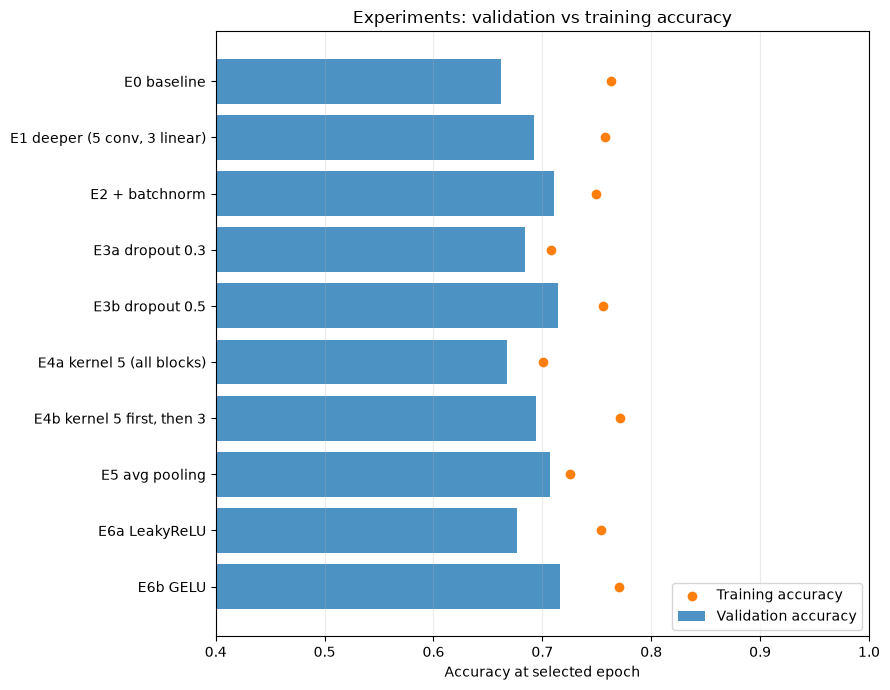

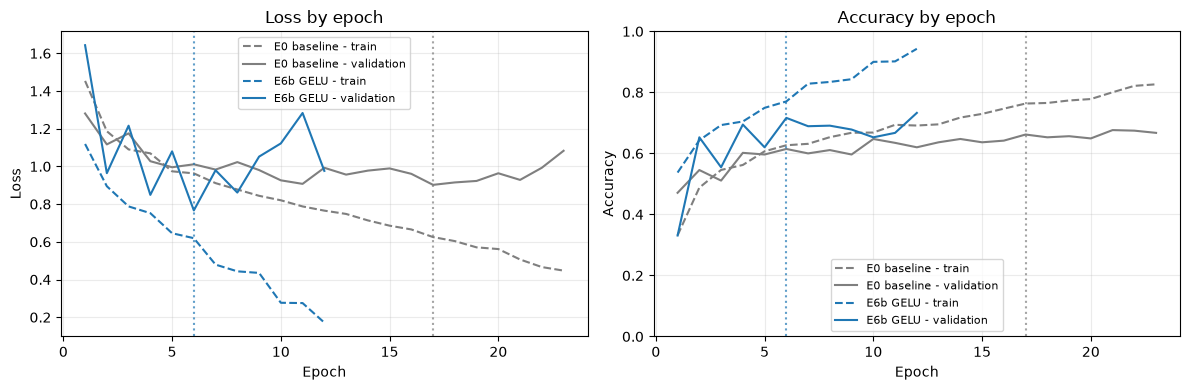

In [20]:
results_table(list(RESULTS))

all_labels = list(RESULTS)
y = np.arange(len(all_labels))
fig, ax = plt.subplots(figsize=(9, 0.55 * len(all_labels) + 1.5))
ax.barh(y, [RESULTS[l]['val_acc'] for l in all_labels], color='tab:blue', alpha=0.8, label='Validation accuracy')
ax.scatter([RESULTS[l]['train_acc'] for l in all_labels], y, color='tab:orange', zorder=3, label='Training accuracy')
ax.set_yticks(y); ax.set_yticklabels(all_labels); ax.invert_yaxis()
ax.set_xlim(0.4, 1.0); ax.set_xlabel('Accuracy at selected epoch'); ax.grid(axis='x', alpha=0.25)
ax.legend(loc='lower right'); ax.set_title('Experiments: validation vs training accuracy')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, color in [(BASE_LABEL, 'tab:gray'), (final_label, 'tab:blue')]:
    h = RESULTS[label]['history']
    ep = np.arange(1, len(h['val_loss']) + 1)
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(ep, h['train_' + metric], '--', color=color, label=f'{label} - train')
        ax.plot(ep, h['val_' + metric], '-', color=color, label=f'{label} - validation')
        ax.axvline(RESULTS[label]['best_epoch'], color=color, linestyle=':', alpha=0.7)
for ax, metric in zip(axes, ['Loss', 'Accuracy']):
    ax.set(xlabel='Epoch', ylabel=metric, title=metric + ' by epoch'); ax.grid(alpha=0.25); ax.legend(fontsize=8)
axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

### Findings

Following the greedy protocol (a change is kept only if it lowers validation loss by more than 0.01), the final model is **E6b**: 5 conv blocks (16->256 filters, 3x3 kernels) with BatchNorm, GELU activations in the conv blocks, max pooling, and a 128 → 64 → 5 classifier with ReLU, with no dropout. 

Relative to the baseline, validation accuracy rose from 66.2% to 71.6%, validation loss fell from 0.902 to 0.767, and the train/validation gap shrank from 10.2 to 5.4 points, with about 2 times the number of parameters. The test accuracy increases from 69.1% in the baseline to 73.3% (this is shown in the section below).


**Observations**

* The added debth helped. Adding two conv blocks and one hidden Linear layer improved validation accuracy by about 3 points and cut the train/validation gap from 10.2 to 6.5 points. Training accuracy stayed about the about the same, so the gain came from better generalization. 
* BatchNorm was the most effective change. It lowered validation loss by 0.077 and reached its best epoch at epoch 6 instead of 19, so it also converges much faster. 
* Dropout did not help once BatchNorm was present. p=0.3 reduced the gap the most (2.4 points) but did so by lowering training accuracy to 70.8%, and validation accuracy fell to 68.4%. p=0.5 reached 71.5% validation accuracy, similar to E2, but its validation loss was still higher (0.826 vs 0.787). BatchNorm already provides regularization, so extra dropout mostly slowed learning. 
* Larger kernels were not worth it. 5×5 everywhere more than doubled the parameters (1.23M) and was worse on every measure (val acc 66.7%, val loss 0.890). Stacked 3×3 layers already build large receptive fields efficiently.
* Activation: GELU won narrowly, LeakyReLU lost. GELU lowered validation loss to 0.767 (0.020 better than ReLU, over the 0.01 margin), but its validation accuracy gain (71.1% -> 71.6%) is inside the noise of a 551-image validation set. Its gap rose from 3.8 to 5.4 points. LeakyReLU was worse than ReLU (0.852).

**Notes on overfitting** 
Every deeper variant had a smaller train/validation gap than the baseline (1.8–7.7 vs 10.2 points). The final model's gap (5.4 points) is about half the baseline's, so overfitting is reduced but not eliminated.



## 9. Evaluate on the test set

All design decisions are finished, so the test set is used now. The next cell reports test loss and accuracy for the baseline and the final model. 

It then makes the final model the `model` used by the detailed report below (which is the original evaluation code).

In [21]:
def load_trained(label):
    m = build_model(CONFIGS[label])
    m.load_state_dict(RESULTS[label]['state'])
    m.eval()
    return m

print(f"{'Model':<32}{'Val acc':>9}{'Test loss':>11}{'Test acc':>10}")
for label in [BASE_LABEL, final_label]:
    t_loss, t_acc = evaluate(load_trained(label), test_loader)
    print(f"{label:<32}{RESULTS[label]['val_acc']:>9.1%}{t_loss:>11.3f}{t_acc:>10.1%}")

model = load_trained(final_label)            # used by the evaluation code below
best_epoch = RESULTS[final_label]['best_epoch']
history = RESULTS[final_label]['history']

Model                             Val acc  Test loss  Test acc
E0 baseline                         66.2%      0.857     69.1%
E6b GELU                            71.6%      0.794     73.3%


Test loss: 0.7941
Test accuracy: 73.32%
Balanced accuracy: 72.47%
Always predict dandelion baseline: 24.50%
              precision    recall  f1-score   support

       daisy       0.68      0.77      0.72        95
   dandelion       0.68      0.90      0.77       135
       roses       0.78      0.53      0.63        96
  sunflowers       0.79      0.83      0.81       105
      tulips       0.81      0.59      0.68       120

    accuracy                           0.73       551
   macro avg       0.75      0.72      0.72       551
weighted avg       0.75      0.73      0.73       551



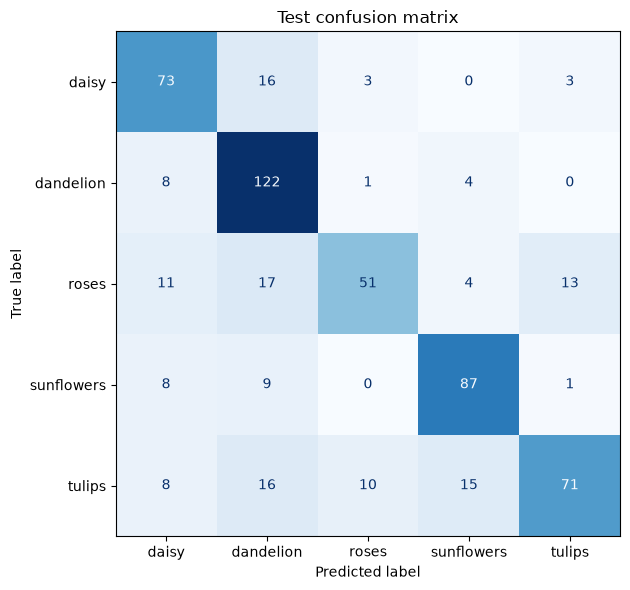

In [22]:
model.eval()
true_labels, predicted_labels, probabilities = [], [], []
test_loss_sum = 0.0
with torch.no_grad():
    for inputs, labels in test_loader:
        logits = model(inputs.to(device))
        test_loss_sum += criterion(logits, labels.to(device)).item() * len(labels)
        # Softmax is useful here to display scores as probabilities.
        # These are model scores, not guarantees or calibrated confidence estimates.
        probabilities.extend(logits.softmax(1).cpu().numpy())
        predicted_labels.extend(logits.argmax(1).cpu().numpy())
        true_labels.extend(labels.numpy())
true_labels = np.asarray(true_labels)
predicted_labels = np.asarray(predicted_labels)
probabilities = np.asarray(probabilities)
test_loss = test_loss_sum / len(true_labels)
test_accuracy = accuracy_score(true_labels, predicted_labels)
balanced_accuracy = balanced_accuracy_score(true_labels, predicted_labels)
majority_class = np.bincount([label for _, label in train_records]).argmax()
baseline_accuracy = np.mean(true_labels == majority_class)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.2%}')
print(f'Balanced accuracy: {balanced_accuracy:.2%}')
print(f'Always predict {class_names[majority_class]} baseline: {baseline_accuracy:.2%}')
print(classification_report(true_labels, predicted_labels,
      labels=list(range(len(class_names))), target_names=class_names, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(true_labels, predicted_labels,
    labels=list(range(len(class_names))), display_labels=class_names,
    cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Test confusion matrix')
plt.tight_layout()
plt.show()

## 10. Inspect predictions and mistakes

Visual inspection helps reveal ambiguous photos and recurring errors. The first grid is a reproducible random test sample; the second contains only mistakes. Correct titles are green and incorrect titles are red.

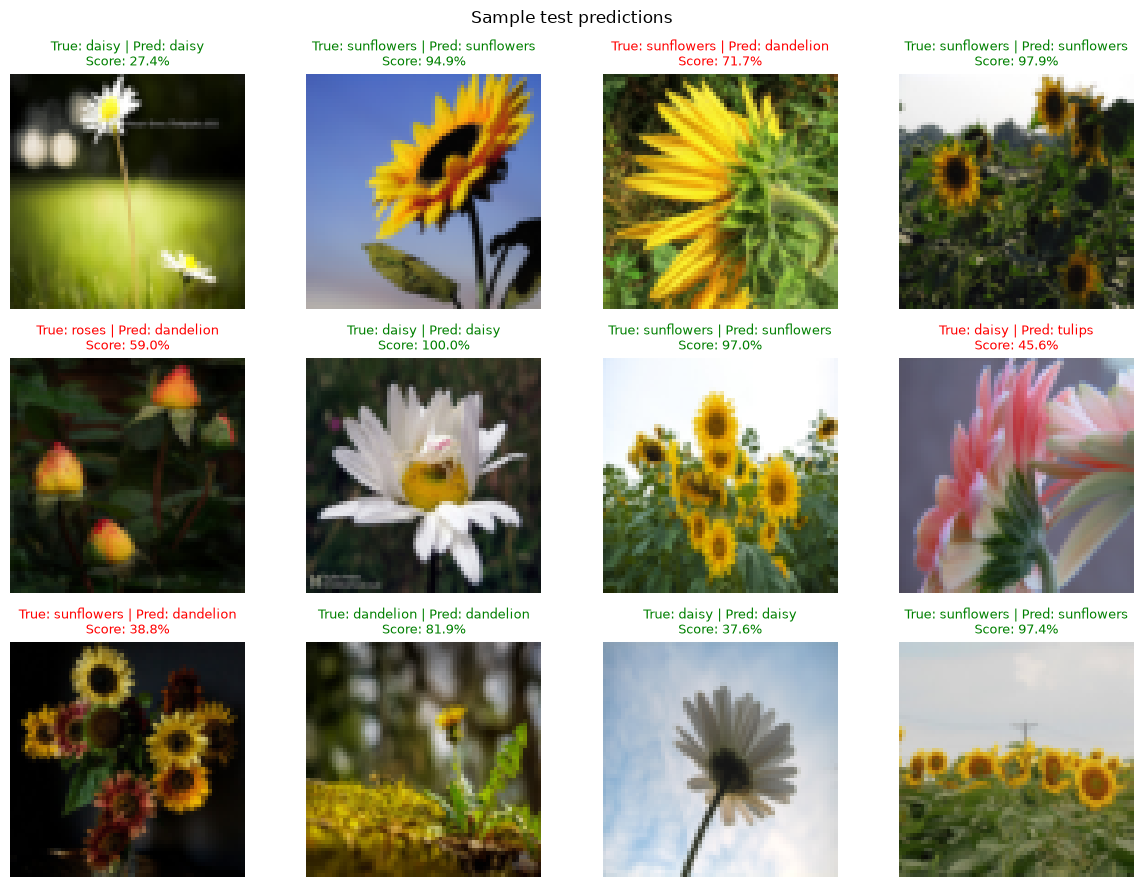

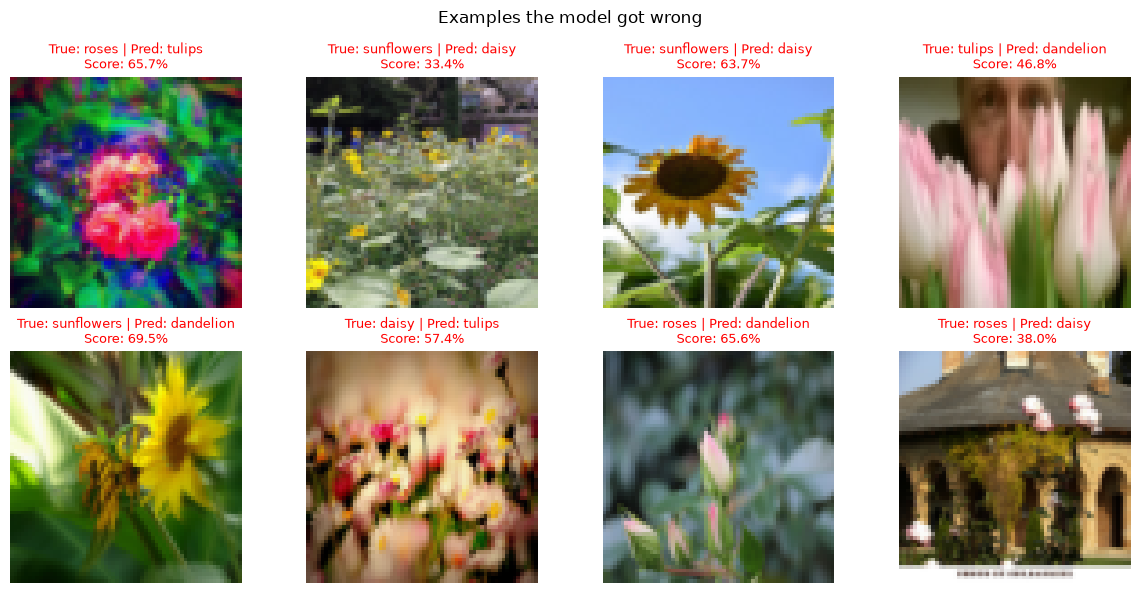

In [23]:
def show_predictions(indices, title):
    if len(indices) == 0:
        print('No mistakes in this test run.')
        return
    fig, axes = plt.subplots((len(indices) + 3) // 4, 4,
                             figsize=(12, 3 * ((len(indices) + 3) // 4)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, indices):
        image, actual = test_dataset[int(index)]
        predicted = predicted_labels[index]
        # Plotting needs H,W,C, whereas PyTorch stores C,H,W.
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(f'True: {class_names[actual]} | Pred: {class_names[predicted]}\n'
                     f'Score: {probabilities[index, predicted]:.1%}',
                     color='green' if actual == predicted else 'red', fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
show_predictions(rng.choice(len(test_dataset), size=12, replace=False), 'Sample test predictions')
errors = np.flatnonzero(true_labels != predicted_labels)
show_predictions(errors[:8], 'Examples the model got wrong')

## 11. Save, reload, and predict one image

We save the weights together with class names and image size so the label mapping is not lost. Reconstruct the same model architecture before loading weights. The example below checks that reloaded weights give the same scores and demonstrates prediction for a single image.

Because the architecture now depends on a config dictionary, the config is saved in the checkpoint and used to rebuild the identical model before loading weights.

In [24]:
OUTPUT_DIR = Path('outputs') / 'flowers'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / 'improved_cnn.pth'
final_cfg = CONFIGS[final_label]
torch.save({
    'state_dict': {key: value.cpu() for key, value in model.state_dict().items()},
    'class_names': class_names, 'image_size': IMAGE_SIZE, 'best_epoch': best_epoch,
    'config': final_cfg, 'experiment': final_label,
}, model_path)
# Store metrics and the full experiment log in a human-readable file.
metrics = {'test_loss': test_loss, 'test_accuracy': test_accuracy,
           'balanced_accuracy': balanced_accuracy, 'majority_baseline_accuracy': float(baseline_accuracy),
           'best_epoch': best_epoch, 'final_experiment': final_label, 'config': final_cfg,
           'history': history,
           'experiments': {label: {'config': CONFIGS[label],
                                   **{k: r[k] for k in ('best_epoch', 'epochs_run', 'best_val_loss',
                                                        'val_acc', 'train_acc', 'params', 'minutes')}}
                           for label, r in RESULTS.items()}}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))

checkpoint = torch.load(model_path, map_location='cpu', weights_only=True)
assert checkpoint['image_size'] == IMAGE_SIZE
reloaded = build_model(checkpoint['config'])
reloaded.load_state_dict(checkpoint['state_dict'])
reloaded.eval()
one_image, actual = test_dataset[0]
with torch.no_grad():
    batch = one_image.unsqueeze(0).to(device)  # Add batch dimension: (1,3,64,64).
    torch.testing.assert_close(model(batch), reloaded(batch))
    predicted = reloaded(batch).argmax(1).item()
print('Reload verified. Example:', checkpoint['class_names'][predicted],
      '| Actual:', class_names[actual])
print('Saved to:', model_path.resolve())

def predict_image(path):
    with Image.open(path) as image:
        batch = image_transform(image.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = reloaded(batch).softmax(1)[0].cpu()
    index = scores.argmax().item()
    return checkpoint['class_names'][index], scores[index].item()

# Replace this with your own photo path to try another image.
print('Single-image prediction:', predict_image(test_records[0][0]))

Reload verified. Example: roses | Actual: roses
Saved to: /home/zoe/Github/deep_learning_course/ps_4/outputs/flowers/improved_cnn.pth
Single-image prediction: ('roses', 0.847640335559845)


# Problem 3

In the 3_Visualizing_Flower_CNN_Filters_PyTorch.ipynb we did an 
introspection of how a Daisy image moves through a CNN and what feature maps are 
created at every block. Now, we have increased the depth of network in problem 2 above, 
we added 2 more convolutional layers (blocks) also added one linear layer with Relu 
activation as well. Make all these changs here in this notebook as well and load our new 
weights. And make sure we can still visualize the daisy.  Notice our Dataset has Roses 
and tulips and other flowers, pick any two other flowers types and see how their feature 
maps look at last block. Also generate grad-CAM heatmap for both flowers and see if it 
truly highlights what makes up that image as a flower.   